In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

# 1.1

In [3]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

start = '2021-01-01'
end = '2025-01-01'
df = yf.download(tickers, start=start, end=end, auto_adjust=False)

close_prices = df['Close']
adj_close_prices = df['Adj Close']
volume_data = df['Volume']

benchmark = yf.download('^GSPC', start=start, end=end, auto_adjust=False)

sp500_df.to_csv('sp500_tickers.csv', index=False)

print(f"Total tickers extracted: {len(tickers)}")
display(sp500_df[['Symbol', 'Security', 'GICS Sector']].head())

#retrieval date
from datetime import date
retrieval_date = date.today()
print("Retrieval Date:", retrieval_date)

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'SNDK', 'Q', 'VYLR', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed

Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology


Retrieval Date: 2026-11-23


# 1.2

In [4]:
duplicate_dates = adj_close_prices.index.duplicated().sum()

missing_values = adj_close_prices.isna().sum()

nonpositive_prices = (adj_close_prices <= 0).sum()

volume_errors = (volume_data <= 0).sum()

history_lengths = adj_close_prices.notna().sum()

corporate_action_flags = (
    (close_prices / adj_close_prices).std(skipna=True) > 0.01
)

print("Duplicate dates:", duplicate_dates)

print("Tickers with missing values:",
      (missing_values > 0).sum())

print("Tickers with non-positive prices:",
      (nonpositive_prices > 0).sum())

print("Tickers with volume errors:",
      (volume_errors > 0).sum())

print("Tickers with incomplete histories:",
      (history_lengths < history_lengths.max()).sum())

print("Tickers with possible corporate actions:",
      corporate_action_flags.sum())

stock_weekly = adj_close_prices.resample("W-FRI").last()
benchmark_weekly = benchmark["Adj Close"].resample("W-FRI").last()

stock_returns = stock_weekly.pct_change(fill_method=None)
benchmark_returns = benchmark_weekly.pct_change(fill_method=None)

common_weeks = stock_returns.index.intersection(
    benchmark_returns.index
)

stock_returns = stock_weekly.pct_change(fill_method=None)
benchmark_returns = benchmark_weekly.pct_change(fill_method=None)

print("Aligned weekly observations:", len(common_weeks))

Duplicate dates: 0
Tickers with missing values: 15
Tickers with non-positive prices: 0
Tickers with volume errors: 2
Tickers with incomplete histories: 15
Tickers with possible corporate actions: 331
Aligned weekly observations: 209


# 1.3.1

In [5]:
stock_weekly = adj_close_prices.resample("W-FRI").last()

benchmark_weekly = benchmark["Adj Close"].resample(
    "W-FRI"
).last()

stock_returns = stock_weekly.pct_change(
    fill_method=None
)

benchmark_returns = benchmark_weekly.pct_change(
    fill_method=None
)

common_weeks = stock_returns.index.intersection(
    benchmark_returns.index
)

stock_returns = stock_returns.loc[common_weeks]
benchmark_returns = benchmark_returns.loc[common_weeks]

stock_returns = stock_returns.iloc[1:]
benchmark_returns = benchmark_returns.iloc[1:]

print(
    "Aligned weekly observations:",
    len(stock_returns)
)

mean_weekly_return = stock_returns.mean()

mean_return_table = pd.DataFrame({
    "Mean Weekly Return": mean_weekly_return,
    "Weekly Std Dev": stock_returns.std(),
    "Min Weekly Return": stock_returns.min(),
    "Max Weekly Return": stock_returns.max(),
    "Valid Weekly Observations": stock_returns.count()
})

mean_return_table = mean_return_table.round(4)

display(mean_return_table.head(10))

Aligned weekly observations: 208


,Mean Weekly Return,Weekly Std Dev,Min Weekly Return,Max Weekly Return,Valid Weekly Observations
Ticker,,,,,
A,0.0011,0.0371,-0.1344,0.1190,208
AAPL,0.0038,0.0355,-0.1100,0.1088,208
ABBV,0.0037,0.0320,-0.1730,0.1017,208
ABNB,0.0014,0.0638,-0.1660,0.2088,208
ABT,0.0009,0.0311,-0.0741,0.0953,208
ACGL,0.0053,0.0331,-0.0881,0.1752,208
ACN,0.0023,0.0362,-0.1057,0.1108,208
ADBE,0.0010,0.0521,-0.2413,0.1939,208
ADI,0.0025,0.0374,-0.0867,0.1370,208


# 1.3.2

In [6]:
stock_weekly = adj_close_prices.resample("W-FRI").last()

benchmark_weekly = benchmark["Adj Close"].resample(
    "W-FRI"
).last()

if isinstance(benchmark_weekly, pd.DataFrame):
    benchmark_weekly = benchmark_weekly.squeeze()

stock_returns = stock_weekly.pct_change(
    fill_method=None
)

benchmark_returns = benchmark_weekly.pct_change(
    fill_method=None
)

common_weeks = stock_returns.index.intersection(
    benchmark_returns.index
)

stock_returns = stock_returns.loc[common_weeks]
benchmark_returns = benchmark_returns.loc[common_weeks]

stock_returns = stock_returns.iloc[1:]
benchmark_returns = benchmark_returns.iloc[1:]

print(
    "Aligned weekly observations:",
    len(stock_returns)
)

benchmark_variance = benchmark_returns.var()

beta_results = []

for ticker in stock_returns.columns:

    aligned = pd.concat(
        [
            stock_returns[ticker],
            benchmark_returns
        ],
        axis=1
    ).dropna()

    if len(aligned) > 1:

        covariance = aligned.iloc[:, 0].cov(
            aligned.iloc[:, 1]
        )

        beta = covariance / benchmark_variance

        beta_results.append(
            [
                ticker,
                beta,
                aligned.iloc[:, 0].mean(),
                len(aligned)
            ]
        )

beta_table = pd.DataFrame(
    beta_results,
    columns=[
        "Ticker",
        "Weekly Beta",
        "Mean Weekly Return",
        "Valid Weekly Observations"
    ]
)

beta_table = beta_table.round(4)

print(
    "\nNumber of Beta Estimates:",
    len(beta_table)
)

display(beta_table.head(10))

beta_table.to_csv(
    "weekly_beta_table.csv",
    index=False
)

Aligned weekly observations: 208

Number of Beta Estimates: 498


,Ticker,Weekly Beta,Mean Weekly Return,Valid Weekly Observations
0,A,1.0729,0.0011,208
1,AAPL,1.1755,0.0038,208
2,ABBV,0.4250,0.0037,208
3,ABNB,1.4711,0.0014,208
4,ABT,0.5848,0.0009,208
5,ACGL,0.5858,0.0053,208
6,ACN,1.1424,0.0023,208
7,ADBE,1.5498,0.0010,208
8,ADI,1.1326,0.0025,208
9,ADM,0.5476,0.0010,208


# 1.4.1

In [7]:
print(close_prices.shape)
print(volume_data.shape)

print(close_prices.index.min())
print(close_prices.index.max())

(1005, 503)
(1005, 503)
2021-01-04 00:00:00
2024-12-31 00:00:00


In [8]:
observation_date = volume_data.index.max()

recency_results = []

for ticker in volume_data.columns:

    volume = volume_data[ticker]

    rolling_mean_20 = (
        volume
        .shift(1)
        .rolling(window=20, min_periods=20)
        .mean()
    )

    threshold = 2 * rolling_mean_20

    high_volume_event = volume > threshold

    event_dates = volume.index[high_volume_event.fillna(False)]

    if len(event_dates) > 0:

        latest_event = event_dates.max()

        recency = (
            observation_date -
            latest_event
        ).days

    else:

        recency = np.nan

    recency_results.append(
        [ticker, recency]
    )

recency_table = pd.DataFrame(
    recency_results,
    columns=[
        "Ticker",
        "Recency"
    ]
)

print("Observation Date:",
      observation_date.date())

display(recency_table.head(10))
recency_table["Recency"].value_counts().head(10)

Observation Date: 2024-12-31


,Ticker,Recency
0,A,11.0
1,AAPL,11.0
2,ABBV,11.0
3,ABNB,11.0
4,ABT,11.0
5,ACGL,11.0
6,ACN,11.0
7,ADBE,18.0
8,ADI,36.0
9,ADM,11.0


,count
Recency,
11.0,358
36.0,17
55.0,11
60.0,6
46.0,6
27.0,5
26.0,5
102.0,5
25.0,5


# 1.4.2

In [9]:
observation_date = volume_data.index.max()

frequency_results = []

for ticker in volume_data.columns:

    volume = volume_data[ticker]

    rolling_mean_20 = (
        volume
        .shift(1)
        .rolling(window=20, min_periods=20)
        .mean()
    )

    threshold = 2 * rolling_mean_20

    high_volume_event = volume > threshold

    last_60_dates = volume.index[
        volume.index <= observation_date
    ][-60:]

    frequency = high_volume_event.loc[
        last_60_dates
    ].sum()

    frequency_results.append(
        [ticker, frequency]
    )

frequency_table = pd.DataFrame(
    frequency_results,
    columns=[
        "Ticker",
        "Frequency"
    ]
)

frequency_table = frequency_table.sort_values(
    by="Frequency",
    ascending=False
)

print(
    "Observation Date:",
    observation_date.date()
)

display(
    frequency_table.head(5)
)

display(
    frequency_table.tail(5)
)

frequency_table["Frequency"].value_counts().head(10)

Observation Date: 2024-12-31


,Ticker,Frequency
90,CI,8
232,HSY,8
192,FOXA,7
495,XEL,7
458,UNH,7


,Ticker,Frequency
229,HRL,0
382,Q,0
178,FCX,0
181,FDXF,0
49,AZO,0


,count
Frequency,
3,153
2,132
4,97
5,48
1,42
0,15
6,11
7,3
8,2


# 1.4.3

In [10]:
observation_date = close_prices.index.max()

last_60_dates = close_prices.index[
    close_prices.index <= observation_date
][-60:]

monetary_results = []

for ticker in close_prices.columns:

    traded_value = (
        close_prices.loc[last_60_dates, ticker]
        *
        volume_data.loc[last_60_dates, ticker]
    )

    monetary = traded_value.sum()

    monetary_results.append(
        [ticker, monetary]
    )

monetary_table = pd.DataFrame(
    monetary_results,
    columns=[
        "Ticker",
        "Monetary"
    ]
)

monetary_table = monetary_table.sort_values(
    by="Monetary",
    ascending=False
)

print(
    "Observation Date:",
    observation_date.date()
)

display(
    monetary_table.head(10)
)


Observation Date: 2024-12-31


,Ticker,Monetary
445,TSLA,1.847697e+12
338,NVDA,1.825337e+12
1,AAPL,6.233034e+11
318,MSFT,5.348982e+11
31,AMZN,4.681770e+11
302,META,4.219106e+11
44,AVGO,3.340388e+11
26,AMD,3.131659e+11
210,GOOGL,2.943802e+11
368,PLTR,2.869115e+11


# 1.5

In [11]:
rfm_table = (
    recency_table
    .merge(frequency_table,
           on="Ticker",
           how="inner")
    .merge(monetary_table,
           on="Ticker",
           how="inner")
)

print("RFM Feature Summary")

display(
    rfm_table[
        ["Recency",
         "Frequency",
         "Monetary"]
    ].describe()
)

included_shares = rfm_table.dropna()

excluded_shares = (
    rfm_table[
        rfm_table.isna().any(axis=1)
    ]
)

print(
    "Included Shares:",
    len(included_shares)
)

print(
    "Excluded Shares:",
    len(excluded_shares)
)

example_ticker = "AAPL"

print(
    "\nWorked Example:",
    example_ticker
)

display(
    rfm_table[
        rfm_table["Ticker"]
        == example_ticker
    ]
)

if len(excluded_shares) > 0:

    print(
        "\nExcluded Tickers"
    )

    display(
        excluded_shares[
            ["Ticker",
             "Recency",
             "Frequency",
             "Monetary"]
        ]
    )

RFM Feature Summary


,Recency,Frequency,Monetary
count,498.000000,503.000000,5.030000e+02
mean,20.510040,2.974155,3.921975e+10
std,21.247722,1.354250,1.273082e+11
min,4.000000,0.000000,0.000000e+00
25%,11.000000,2.000000,1.001055e+10
50%,11.000000,3.000000,1.659094e+10
75%,18.000000,4.000000,3.257858e+10
max,222.000000,8.000000,1.847697e+12


Included Shares: 498
Excluded Shares: 5

Worked Example: AAPL


,Ticker,Recency,Frequency,Monetary
1,AAPL,11.0,2,6.233034e+11



Excluded Tickers


,Ticker,Recency,Frequency,Monetary
181,FDXF,NaN,0,0.0
225,HONA,NaN,0,0.0
382,Q,NaN,0,0.0
408,SNDK,NaN,0,0.0
477,VYLR,NaN,0,0.0


# 2.1

In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [13]:
risk_return = beta_table[
    ['Ticker', 'Mean Weekly Return', 'Weekly Beta']
].copy()

feature_table = rfm_table.merge(
    risk_return,
    on='Ticker',
    how='inner'
)

feature_table = feature_table.dropna()

print(feature_table.head())
print(feature_table.shape)

  Ticker  Recency  Frequency      Monetary  Mean Weekly Return  Weekly Beta
0      A     11.0          2  1.400180e+10              0.0011       1.0729
1   AAPL     11.0          2  6.233034e+11              0.0038       1.1755
2   ABBV     11.0          3  6.837054e+10              0.0037       0.4250
3   ABNB     11.0          3  3.652850e+10              0.0014       1.4711
4    ABT     11.0          1  3.523027e+10              0.0009       0.5848
(498, 6)


Risk & Return Skewness
Mean Weekly Return    3.235867
Weekly Beta           1.228290
dtype: float64

RFM Skewness
Recency       3.610175
Frequency     0.407012
Monetary     11.739518
dtype: float64


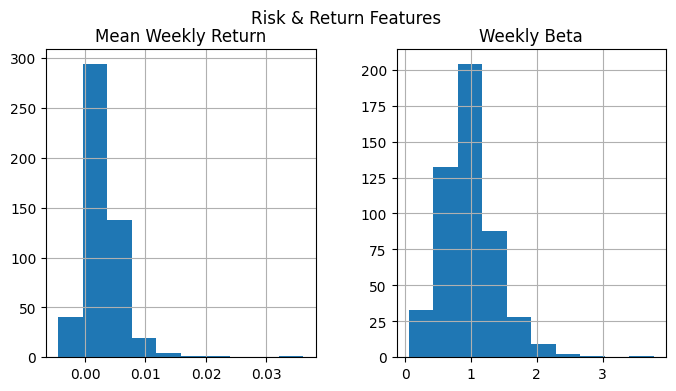

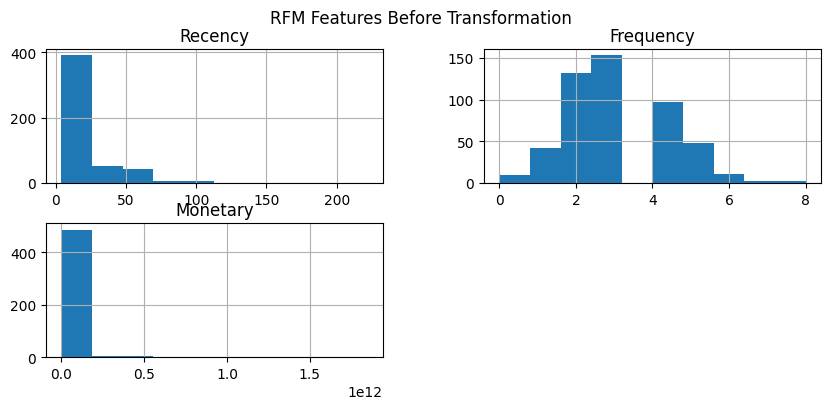

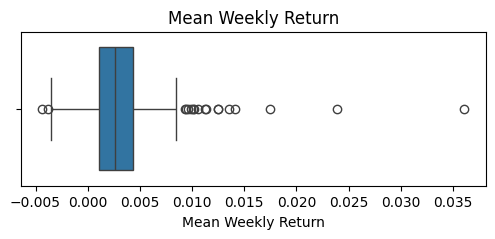

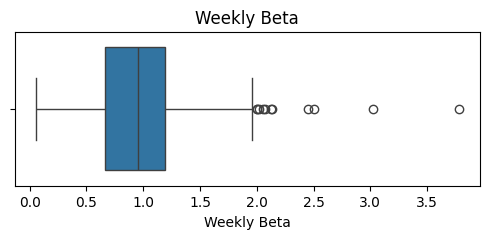

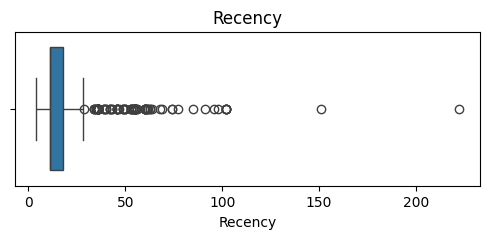

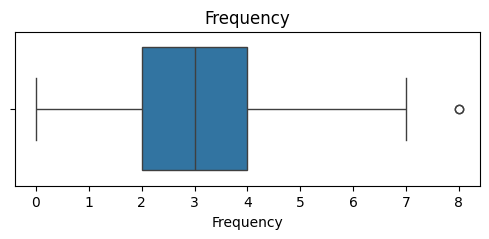

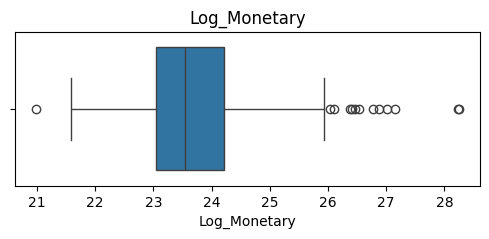


Risk/Return Scaled Summary
       Mean Weekly Return   Weekly Beta
count        4.980000e+02  4.980000e+02
mean         3.566982e-17  4.458727e-17
std          1.001006e+00  1.001006e+00
min         -2.290039e+00 -2.179233e+00
25%         -5.738664e-01 -7.382538e-01
50%         -1.157026e-01 -6.897944e-02
75%          4.123505e-01  4.886116e-01
max          1.029005e+01  6.596535e+00

RFM Scaled Summary
            Recency     Frequency  Log_Monetary
count  4.980000e+02  4.980000e+02  4.980000e+02
mean  -3.566982e-17 -5.528821e-17  1.366154e-15
std    1.001006e+00  1.001006e+00  1.001006e+00
min   -7.778077e-01 -2.264993e+00 -2.859829e+00
25%   -4.480293e-01 -7.570164e-01 -6.758610e-01
50%   -4.480293e-01 -3.028065e-03 -1.541163e-01
75%   -1.182510e-01  7.509602e-01  5.554403e-01
max    9.492432e+00  3.766913e+00  4.812522e+00

Risk & Return Shape: (498, 2)
RFM Shape: (498, 3)


In [14]:
rr_features = feature_table[
    ['Mean Weekly Return', 'Weekly Beta']
].copy()


rfm_features = feature_table[
    ['Recency', 'Frequency', 'Monetary']
].copy()


print("Risk & Return Skewness")
print(rr_features.skew())

print("\nRFM Skewness")
print(rfm_features.skew())


rr_features.hist(figsize=(8,4))
plt.suptitle("Risk & Return Features")
plt.show()

rfm_features.hist(figsize=(10,4))
plt.suptitle("RFM Features Before Transformation")
plt.show()


rfm_features['Log_Monetary'] = np.log1p(
    rfm_features['Monetary']
)

rfm_features.drop(
    columns='Monetary',
    inplace=True
)


for col in rr_features.columns:
    plt.figure(figsize=(6,2))
    sns.boxplot(x=rr_features[col])
    plt.title(col)
    plt.show()

for col in rfm_features.columns:
    plt.figure(figsize=(6,2))
    sns.boxplot(x=rfm_features[col])
    plt.title(col)
    plt.show()


rr_scaled = pd.DataFrame(
    StandardScaler().fit_transform(rr_features),
    columns=rr_features.columns,
    index=rr_features.index
)

rfm_scaled = pd.DataFrame(
    StandardScaler().fit_transform(rfm_features),
    columns=rfm_features.columns,
    index=rfm_features.index
)


print("\nRisk/Return Scaled Summary")
print(rr_scaled.describe())

print("\nRFM Scaled Summary")
print(rfm_scaled.describe())

print("\nRisk & Return Shape:", rr_scaled.shape)
print("RFM Shape:", rfm_scaled.shape)

# 2.2

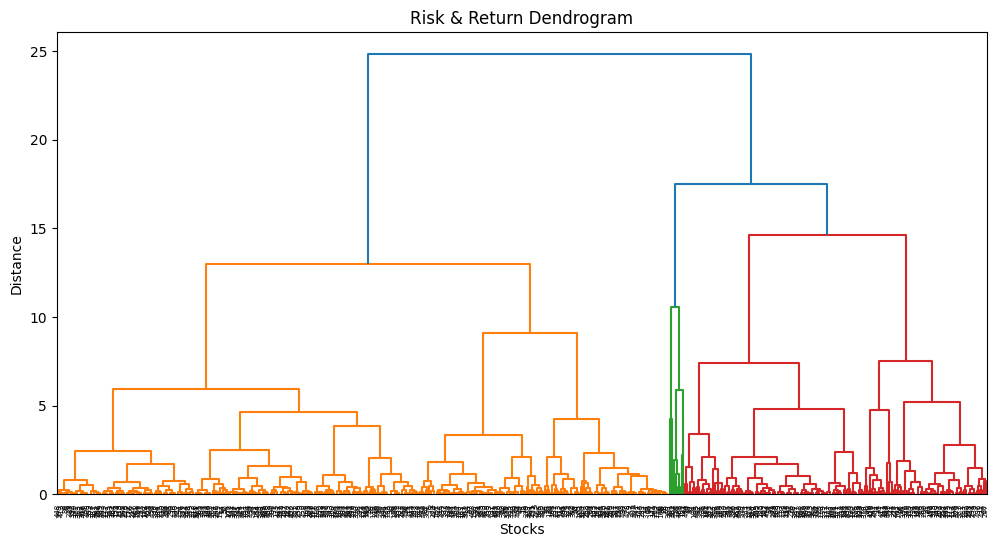

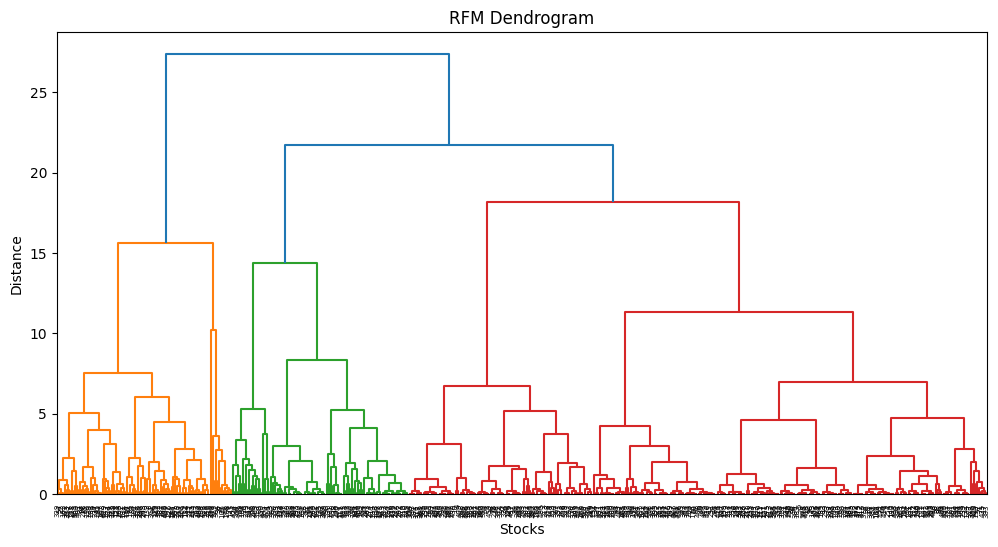

RISK & RETURN RESULTS

Clusters = 2
Silhouette = 0.373
Sizes:
0    170
1    328
Name: count, dtype: int64

Clusters = 3
Silhouette = 0.3655
Sizes:
0    162
1    328
2      8
Name: count, dtype: int64

Clusters = 4
Silhouette = 0.3599
Sizes:
0    328
1     66
2      8
3     96
Name: count, dtype: int64

Clusters = 5
Silhouette = 0.3259
Sizes:
0      8
1     66
2    134
3     96
4    194
Name: count, dtype: int64

Clusters = 6
Silhouette = 0.3294
Sizes:
0    134
1     66
2      6
3     96
4    194
5      2
Name: count, dtype: int64

Clusters = 7
Silhouette = 0.3361
Sizes:
0     66
1     96
2      6
3     67
4    194
5      2
6     67
Name: count, dtype: int64

Clusters = 8
Silhouette = 0.3447
Sizes:
0     96
1    194
2      6
3     16
4     50
5      2
6     67
7     67
Name: count, dtype: int64


RFM RESULTS

Clusters = 2
Silhouette = 0.3587
Sizes:
0    404
1     94
Name: count, dtype: int64

Clusters = 3
Silhouette = 0.316
Sizes:
0    310
1     94
2     94
Name: count, dtype: int64

Cl

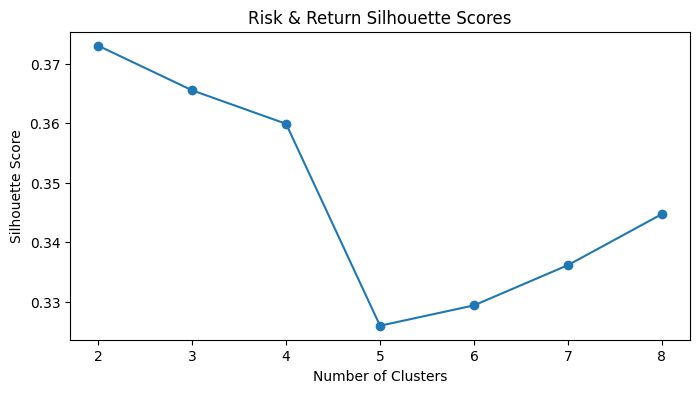

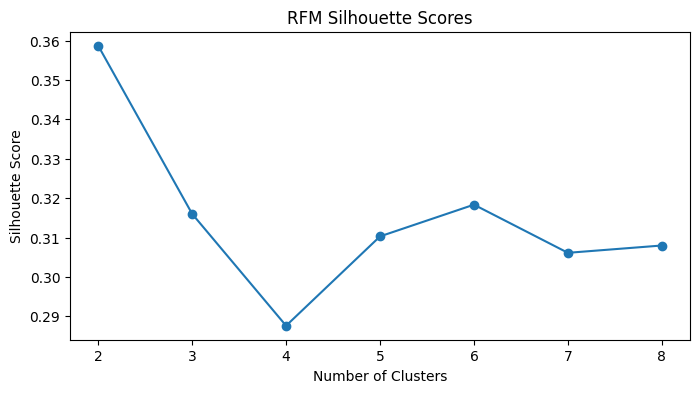


Risk & Return Summary
   Clusters  Silhouette
0         2    0.373001
1         3    0.365505
2         4    0.359877
3         5    0.325948
4         6    0.329365
5         7    0.336127
6         8    0.344704

RFM Summary
   Clusters  Silhouette
0         2    0.358679
1         3    0.316000
2         4    0.287608
3         5    0.310284
4         6    0.318334
5         7    0.306113
6         8    0.307970

Best Risk & Return K = 2
Best RFM K = 2

Cluster labels added to feature_table


,Ticker,Recency,Frequency,Monetary,Mean Weekly Return,Weekly Beta,RR_Ward_Cluster,RFM_Ward_Cluster
0,A,11.0,2,1.400180e+10,0.0011,1.0729,1,0
1,AAPL,11.0,2,6.233034e+11,0.0038,1.1755,0,0
2,ABBV,11.0,3,6.837054e+10,0.0037,0.4250,1,0
3,ABNB,11.0,3,3.652850e+10,0.0014,1.4711,0,0
4,ABT,11.0,1,3.523027e+10,0.0009,0.5848,1,0


In [15]:
plt.figure(figsize=(12,6))

rr_linkage = linkage(
    rr_scaled,
    method='ward'
)

dendrogram(rr_linkage)

plt.title('Risk & Return Dendrogram')
plt.xlabel('Stocks')
plt.ylabel('Distance')
plt.show()


plt.figure(figsize=(12,6))

rfm_linkage = linkage(
    rfm_scaled,
    method='ward'
)

dendrogram(rfm_linkage)

plt.title('RFM Dendrogram')
plt.xlabel('Stocks')
plt.ylabel('Distance')
plt.show()


rr_results = []

print("RISK & RETURN RESULTS")

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(rr_scaled)

    silhouette = silhouette_score(
        rr_scaled,
        labels
    )

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    print(f"\nClusters = {k}")
    print("Silhouette =", round(silhouette,4))
    print("Sizes:")
    print(cluster_sizes)

    rr_results.append([
        k,
        silhouette
    ])

rr_results = pd.DataFrame(
    rr_results,
    columns=['Clusters','Silhouette']
)


rfm_results = []

print("\n\nRFM RESULTS")

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(rfm_scaled)

    silhouette = silhouette_score(
        rfm_scaled,
        labels
    )

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    print(f"\nClusters = {k}")
    print("Silhouette =", round(silhouette,4))
    print("Sizes:")
    print(cluster_sizes)

    rfm_results.append([
        k,
        silhouette
    ])

rfm_results = pd.DataFrame(
    rfm_results,
    columns=['Clusters','Silhouette']
)


plt.figure(figsize=(8,4))

plt.plot(
    rr_results['Clusters'],
    rr_results['Silhouette'],
    marker='o'
)

plt.title('Risk & Return Silhouette Scores')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.show()

plt.figure(figsize=(8,4))

plt.plot(
    rfm_results['Clusters'],
    rfm_results['Silhouette'],
    marker='o'
)

plt.title('RFM Silhouette Scores')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.show()


print("\nRisk & Return Summary")
print(rr_results)

print("\nRFM Summary")
print(rfm_results)


best_rr_k = rr_results.loc[
    rr_results['Silhouette'].idxmax(),
    'Clusters'
]

best_rfm_k = rfm_results.loc[
    rfm_results['Silhouette'].idxmax(),
    'Clusters'
]

print("\nBest Risk & Return K =", best_rr_k)
print("Best RFM K =", best_rfm_k)


rr_model = AgglomerativeClustering(
    n_clusters=int(best_rr_k),
    linkage='ward'
)

rfm_model = AgglomerativeClustering(
    n_clusters=int(best_rfm_k),
    linkage='ward'
)

rr_labels = rr_model.fit_predict(rr_scaled)
rfm_labels = rfm_model.fit_predict(rfm_scaled)


feature_table['RR_Ward_Cluster'] = rr_labels
feature_table['RFM_Ward_Cluster'] = rfm_labels

print("\nCluster labels added to feature_table")

feature_table.head()

In [16]:
rr_results

,Clusters,Silhouette
0,2,0.373001
1,3,0.365505
2,4,0.359877
3,5,0.325948
4,6,0.329365
5,7,0.336127
6,8,0.344704


In [17]:
rfm_results

,Clusters,Silhouette
0,2,0.358679
1,3,0.316000
2,4,0.287608
3,5,0.310284
4,6,0.318334
5,7,0.306113
6,8,0.307970


In [18]:
rr_model = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

rfm_model = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

rr_labels = rr_model.fit_predict(rr_scaled)
rfm_labels = rfm_model.fit_predict(rfm_scaled)

feature_table['RR_Ward_Cluster'] = rr_labels
feature_table['RFM_Ward_Cluster'] = rfm_labels

print(feature_table['RR_Ward_Cluster'].value_counts())

print(feature_table['RFM_Ward_Cluster'].value_counts())

RR_Ward_Cluster
1    328
0    170
Name: count, dtype: int64
RFM_Ward_Cluster
0    404
1     94
Name: count, dtype: int64


# 2.3

   Clusters  Silhouette     Inertia
0         2    0.398072  659.416661
1         3    0.344318  505.404319
2         4    0.337925  395.499125
3         5    0.347827  324.789492
4         6    0.352711  269.602689
5         7    0.340067  228.911450
6         8    0.331499  196.951800
   Clusters  Silhouette      Inertia
0         2    0.418999  1094.049704
1         3    0.324539   818.237455
2         4    0.340100   625.239576
3         5    0.356812   528.698704
4         6    0.346771   447.487971
5         7    0.348644   396.278791
6         8    0.347018   354.681706


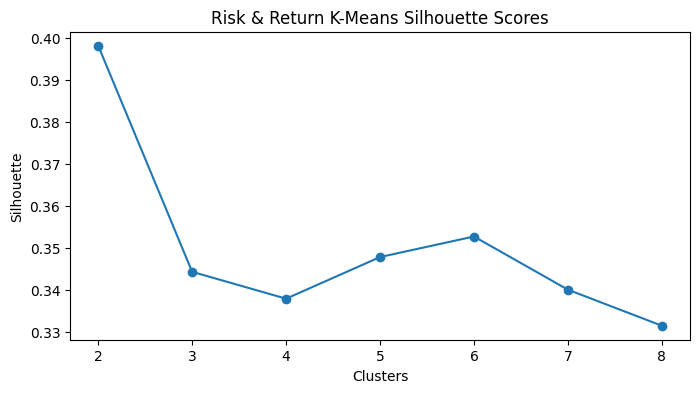

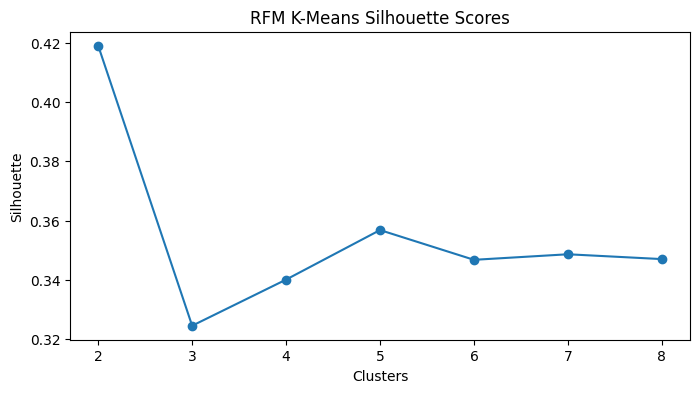

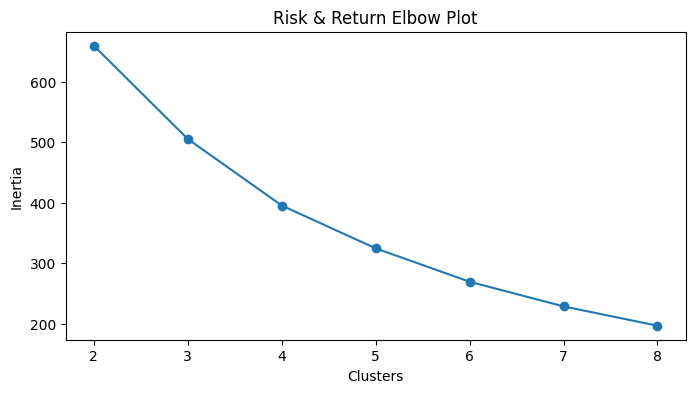

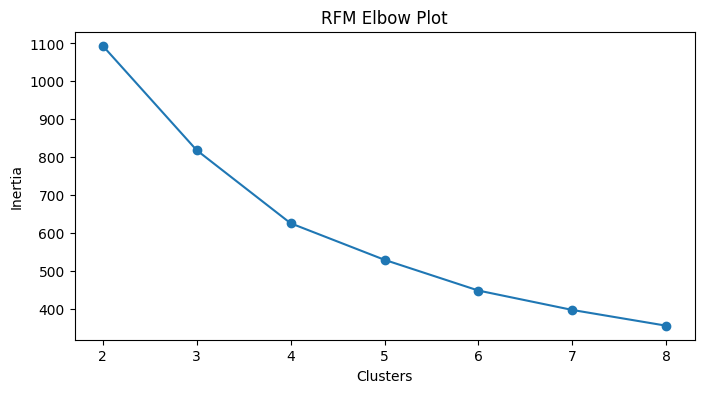

In [19]:
rr_kmeans_results = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(rr_scaled)

    silhouette = silhouette_score(
        rr_scaled,
        labels
    )

    inertia = model.inertia_

    rr_kmeans_results.append([
        k,
        silhouette,
        inertia
    ])

rr_kmeans_results = pd.DataFrame(
    rr_kmeans_results,
    columns=["Clusters", "Silhouette", "Inertia"]
)

print(rr_kmeans_results)


rfm_kmeans_results = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(rfm_scaled)

    silhouette = silhouette_score(
        rfm_scaled,
        labels
    )

    inertia = model.inertia_

    rfm_kmeans_results.append([
        k,
        silhouette,
        inertia
    ])

rfm_kmeans_results = pd.DataFrame(
    rfm_kmeans_results,
    columns=["Clusters", "Silhouette", "Inertia"]
)

print(rfm_kmeans_results)


plt.figure(figsize=(8,4))
plt.plot(
    rr_kmeans_results["Clusters"],
    rr_kmeans_results["Silhouette"],
    marker="o"
)
plt.title("Risk & Return K-Means Silhouette Scores")
plt.xlabel("Clusters")
plt.ylabel("Silhouette")
plt.show()

plt.figure(figsize=(8,4))
plt.plot(
    rfm_kmeans_results["Clusters"],
    rfm_kmeans_results["Silhouette"],
    marker="o"
)
plt.title("RFM K-Means Silhouette Scores")
plt.xlabel("Clusters")
plt.ylabel("Silhouette")
plt.show()


plt.figure(figsize=(8,4))
plt.plot(
    rr_kmeans_results["Clusters"],
    rr_kmeans_results["Inertia"],
    marker="o"
)
plt.title("Risk & Return Elbow Plot")
plt.xlabel("Clusters")
plt.ylabel("Inertia")
plt.show()

plt.figure(figsize=(8,4))
plt.plot(
    rfm_kmeans_results["Clusters"],
    rfm_kmeans_results["Inertia"],
    marker="o"
)
plt.title("RFM Elbow Plot")
plt.xlabel("Clusters")
plt.ylabel("Inertia")
plt.show()


# 2.4


WARD - RISK & RETURN
                 Mean Weekly Return  Weekly Beta
RR_Ward_Cluster                                 
0                          0.004659     1.387260
1                          0.002098     0.769543

K-MEANS - RISK & RETURN
                   Mean Weekly Return  Weekly Beta
RR_KMeans_Cluster                                 
0                            0.001988     0.795703
1                            0.005322     1.421446

WARD - RFM
                    Recency  Frequency      Monetary
RFM_Ward_Cluster                                    
0                 12.361386   3.220297  3.820898e+10
1                 55.531915   2.074468  4.565006e+10

K-MEANS - RFM
                      Recency  Frequency      Monetary
RFM_KMeans_Cluster                                    
0                   62.486111   1.847222  8.060058e+10
1                   13.415493   3.199531  3.268613e+10


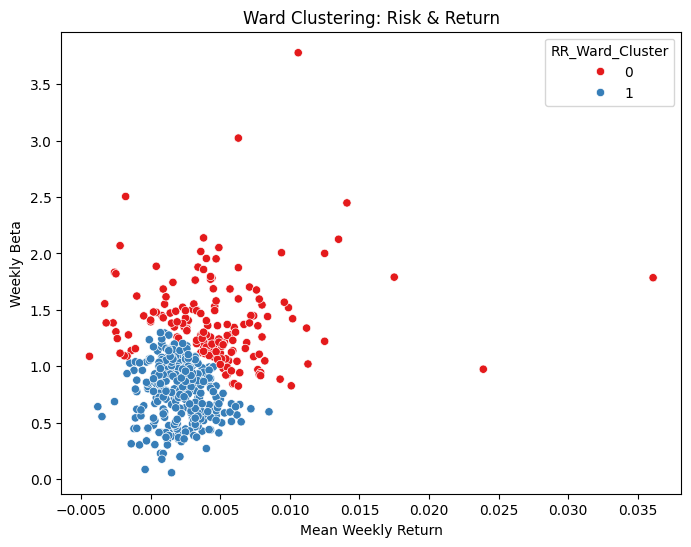

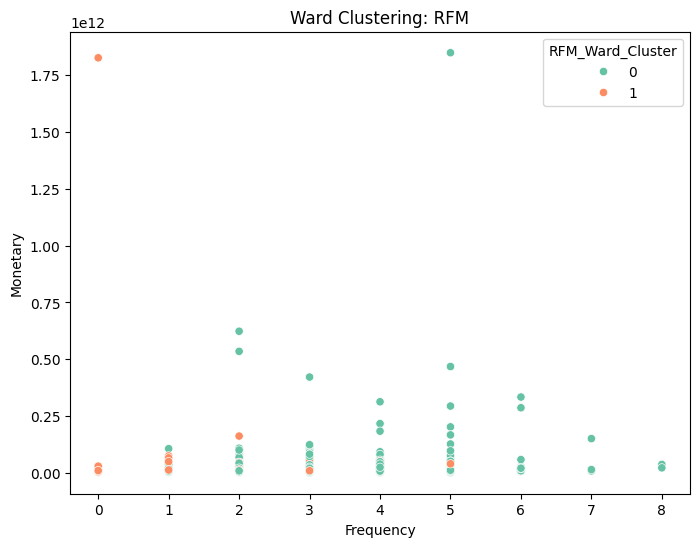


Ward Risk & Return Cluster Sizes
RR_Ward_Cluster
1    328
0    170
Name: count, dtype: int64

K-Means Risk & Return Cluster Sizes
RR_KMeans_Cluster
0    351
1    147
Name: count, dtype: int64

Ward RFM Cluster Sizes
RFM_Ward_Cluster
0    404
1     94
Name: count, dtype: int64

K-Means RFM Cluster Sizes
RFM_KMeans_Cluster
1    426
0     72
Name: count, dtype: int64


In [20]:
kmeans_rr = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

feature_table['RR_KMeans_Cluster'] = (
    kmeans_rr.fit_predict(rr_scaled)
)

kmeans_rfm = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

feature_table['RFM_KMeans_Cluster'] = (
    kmeans_rfm.fit_predict(rfm_scaled)
)


print("\nWARD - RISK & RETURN")
rr_profile = feature_table.groupby(
    'RR_Ward_Cluster'
)[['Mean Weekly Return','Weekly Beta']].mean()

print(rr_profile)

print("\nK-MEANS - RISK & RETURN")
rr_kmeans_profile = feature_table.groupby(
    'RR_KMeans_Cluster'
)[['Mean Weekly Return','Weekly Beta']].mean()

print(rr_kmeans_profile)

print("\nWARD - RFM")
rfm_profile = feature_table.groupby(
    'RFM_Ward_Cluster'
)[['Recency','Frequency','Monetary']].mean()

print(rfm_profile)

print("\nK-MEANS - RFM")
rfm_kmeans_profile = feature_table.groupby(
    'RFM_KMeans_Cluster'
)[['Recency','Frequency','Monetary']].mean()

print(rfm_kmeans_profile)


plt.figure(figsize=(8,6))

sns.scatterplot(
    data=feature_table,
    x='Mean Weekly Return',
    y='Weekly Beta',
    hue='RR_Ward_Cluster',
    palette='Set1'
)

plt.title('Ward Clustering: Risk & Return')
plt.show()


plt.figure(figsize=(8,6))

sns.scatterplot(
    data=feature_table,
    x='Frequency',
    y='Monetary',
    hue='RFM_Ward_Cluster',
    palette='Set2'
)

plt.title('Ward Clustering: RFM')
plt.show()


print("\nWard Risk & Return Cluster Sizes")
print(
    feature_table['RR_Ward_Cluster']
    .value_counts()
)

print("\nK-Means Risk & Return Cluster Sizes")
print(
    feature_table['RR_KMeans_Cluster']
    .value_counts()
)

print("\nWard RFM Cluster Sizes")
print(
    feature_table['RFM_Ward_Cluster']
    .value_counts()
)

print("\nK-Means RFM Cluster Sizes")
print(
    feature_table['RFM_KMeans_Cluster']
    .value_counts()
)


In [21]:
rr_profile
rr_kmeans_profile
rfm_profile
rfm_kmeans_profile

,Recency,Frequency,Monetary
RFM_KMeans_Cluster,,,
0,62.486111,1.847222,8.060058e+10
1,13.415493,3.199531,3.268613e+10


In [22]:
rr_profile
rr_kmeans_profile
rfm_profile

,Recency,Frequency,Monetary
RFM_Ward_Cluster,,,
0,12.361386,3.220297,3.820898e+10
1,55.531915,2.074468,4.565006e+10


# 2.5.1

               Recency  Frequency  Log_Monetary
Recency       1.000000  -0.340235      0.164673
Frequency    -0.340235   1.000000      0.021868
Log_Monetary  0.164673   0.021868      1.000000


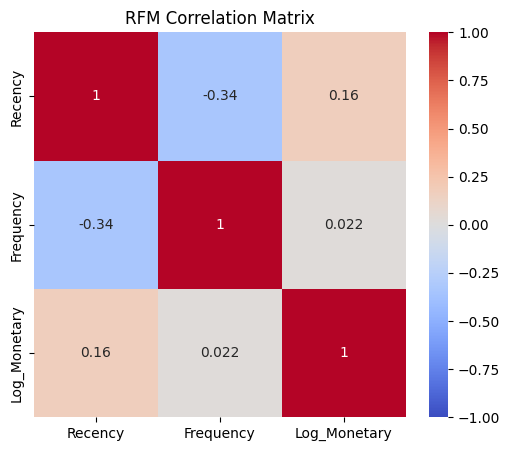

In [23]:
corr_matrix = rfm_features.corr()

print(corr_matrix)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title("RFM Correlation Matrix")
plt.show()

# 2.5.2

In [24]:
rf_features = feature_table[
    ['Recency', 'Frequency']
].copy()


rf_scaled = pd.DataFrame(
    StandardScaler().fit_transform(rf_features),
    columns=rf_features.columns,
    index=rf_features.index
)


rf_model = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

rf_labels = rf_model.fit_predict(rf_scaled)

feature_table['RF_Ward_Cluster'] = rf_labels


ari = adjusted_rand_score(
    feature_table['RFM_Ward_Cluster'],
    feature_table['RF_Ward_Cluster']
)

print("Adjusted Rand Index =", round(ari,4))


print("\nOriginal RFM Clusters")
print(
    feature_table.groupby(
        'RFM_Ward_Cluster'
    )[['Recency','Frequency','Monetary']]
    .mean()
)

print("\nRF Clusters (Monetary Removed)")
print(
    feature_table.groupby(
        'RF_Ward_Cluster'
    )[['Recency','Frequency','Monetary']]
    .mean()
)


print("\nOriginal RFM Cluster Sizes")
print(
    feature_table['RFM_Ward_Cluster']
    .value_counts()
)

print("\nRF Cluster Sizes")
print(
    feature_table['RF_Ward_Cluster']
    .value_counts()
)

Adjusted Rand Index = 0.9531

Original RFM Clusters
                    Recency  Frequency      Monetary
RFM_Ward_Cluster                                    
0                 12.361386   3.220297  3.820898e+10
1                 55.531915   2.074468  4.565006e+10

RF Clusters (Monetary Removed)
                   Recency  Frequency      Monetary
RF_Ward_Cluster                                    
0                12.353086   3.222222  3.768854e+10
1                56.032258   2.053763  4.799647e+10

Original RFM Cluster Sizes
RFM_Ward_Cluster
0    404
1     94
Name: count, dtype: int64

RF Cluster Sizes
RF_Ward_Cluster
0    405
1     93
Name: count, dtype: int64


# 3.2.1


Risk & Return Profiles
                 Mean Weekly Return  Weekly Beta
RR_Ward_Cluster                                 
0                          0.004659     1.387260
1                          0.002098     0.769543

RFM Profiles
                    Recency  Frequency      Monetary
RFM_Ward_Cluster                                    
0                 12.361386   3.220297  3.820898e+10
1                 55.531915   2.074468  4.565006e+10

Risk & Return Sector Composition
GICS Sector      Communication Services  Consumer Discretionary  \
RR_Ward_Cluster                                                   
0                                     8                      24   
1                                    14                      23   

GICS Sector      Consumer Staples  Energy  Financials  Health Care  \
RR_Ward_Cluster                                                      
0                               2       8          24            6   
1                              29      13

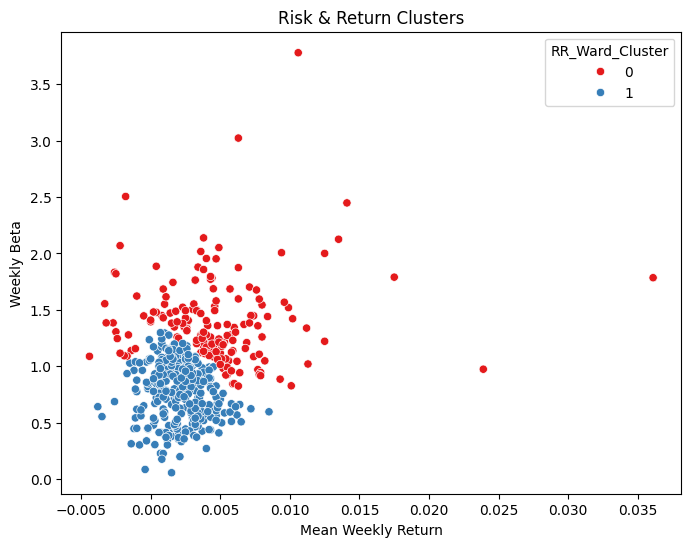

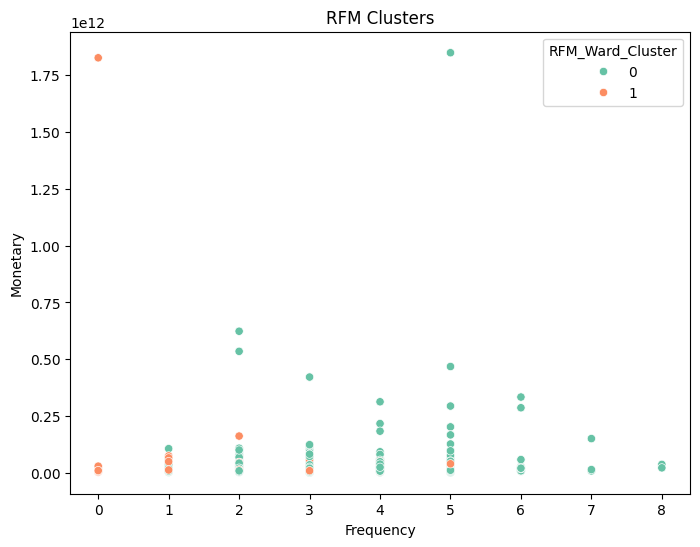

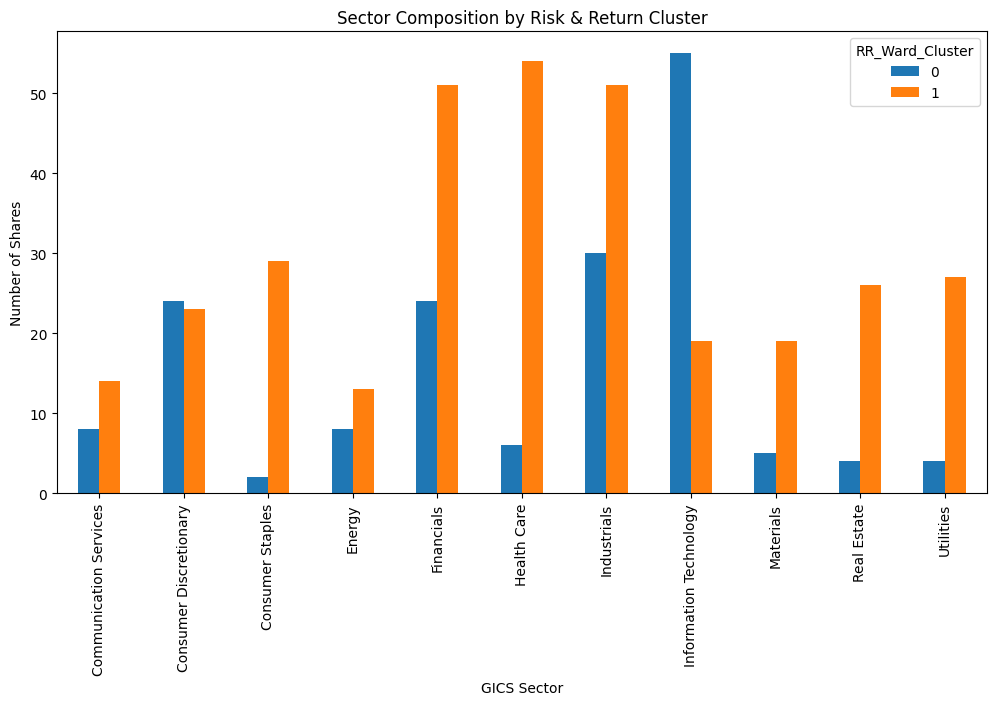

In [34]:
feature_sector = feature_table.merge(
    sp500_df[['Symbol','GICS Sector']],
    left_on='Ticker',
    right_on='Symbol',
    how='left'
)


rr_profile = feature_sector.groupby(
    'RR_Ward_Cluster'
)[['Mean Weekly Return','Weekly Beta']].mean()

print("\nRisk & Return Profiles")
print(rr_profile)


rfm_profile = feature_sector.groupby(
    'RFM_Ward_Cluster'
)[['Recency','Frequency','Monetary']].mean()

print("\nRFM Profiles")
print(rfm_profile)


rr_sector = pd.crosstab(
    feature_sector['RR_Ward_Cluster'],
    feature_sector['GICS Sector']
)

print("\nRisk & Return Sector Composition")
print(rr_sector)

rfm_sector = pd.crosstab(
    feature_sector['RFM_Ward_Cluster'],
    feature_sector['GICS Sector']
)

print("\nRFM Sector Composition")
print(rfm_sector)


plt.figure(figsize=(8,6))

sns.scatterplot(
    data=feature_sector,
    x='Mean Weekly Return',
    y='Weekly Beta',
    hue='RR_Ward_Cluster',
    palette='Set1'
)

plt.title('Risk & Return Clusters')
plt.show()


plt.figure(figsize=(8,6))

sns.scatterplot(
    data=feature_sector,
    x='Frequency',
    y='Monetary',
    hue='RFM_Ward_Cluster',
    palette='Set2'
)

plt.title('RFM Clusters')
plt.show()


rr_sector.T.plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Sector Composition by Risk & Return Cluster')
plt.ylabel('Number of Shares')
plt.show()